# 02. Purchase Pattern Analysis | ROKEY 편의점 로봇
기존 `Instacart_추천_분석(1).ipynb`의 후속 노트북. **R(재구매), S(동일 코너), C(다른 코너)**를 계산하고 03번 추천 엔진과 04번 평가 노트북에 전달한다.

- 원본 CSV는 기존 Drive 경로를 재사용한다. CPU 런타임 권장.
- prior만 점수 계산에 사용한다. train은 다음 단계 평가용으로 보존한다.
- 기존 파일을 덮어쓰지 않고 `recommender/pattern_analysis_v2`에 저장한다.
- 상품 매핑은 한국 SKU의 직접 대응이 아닌 대리 상품군이다. 특히 참치/스팸은 별도 키워드 매핑을 검토해야 한다. 다른 상품은 현재 aisle 대리값이다.
- 초기 기준(동시 구매 200건, 작은 장바구니 2~5 코너)은 실험용이며 최적값이 아니다. 이 노트북은 최종 성능 평가나 웹 연동을 하지 않는다.

## 0. 환경 설정 및 원본 파일 확인

In [1]:
from pathlib import Path
import json, gc
import numpy as np
import pandas as pd
from scipy import sparse
from IPython.display import display
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')
BASE = Path('/content/drive/MyDrive/2026_02_ROKEY/07_cobot2')
DATA = BASE / 'instacart'
OUT = BASE / 'recommender' / 'pattern_analysis_v2'
OUT.mkdir(parents=True, exist_ok=True)
CHUNK = 1_000_000
MIN_COUNT = 200
required = ['orders.csv','products.csv','aisles.csv','departments.csv','order_products__prior.csv','order_products__train.csv']
missing = [f for f in required if not (DATA/f).exists()]
if missing:
    raise FileNotFoundError(f'기존 01 노트북에서 데이터 다운로드 먼저 실행: {missing}')
print('저장 위치:', OUT)

Mounted at /content/drive
저장 위치: /content/drive/MyDrive/2026_02_ROKEY/07_cobot2/recommender/pattern_analysis_v2


## 1. 데이터 로드 및 기존 상품 매핑 유지
전체 3,243만 행을 한꺼번에 merge하지 않고 CSV를 청크 단위로 읽는다. 주문 및 상품 메타데이터는 메모리에 유지한다.

In [2]:
products = pd.read_csv(DATA/'products.csv', dtype={'product_id':'int32','aisle_id':'int16','department_id':'int16'})
aisles = pd.read_csv(DATA/'aisles.csv')
departments = pd.read_csv(DATA/'departments.csv')
orders = pd.read_csv(DATA/'orders.csv', usecols=['order_id','user_id','order_number','eval_set'], dtype={'order_id':'int32','user_id':'int32','order_number':'int16'})
prior_orders = orders.loc[orders.eval_set.eq('prior')].sort_values('order_id').reset_index(drop=True)
assert prior_orders.order_id.is_unique and products.product_id.is_unique
OURS = pd.DataFrame([
    # id,          이름,        aisle_id, 로봇
    ("tuna_can",    "참치캔",      95, True),
    ("spam_can",    "스팸 통조림",  95, True),
    ("milk_pack",   "소형 우유팩",  84, True),
    ("soap_box",    "비누 상자",    25, True),
    ("choco_box",   "초콜릿 상자",  45, True),
    ("snack_bag",   "과자 봉지",   107, True),
    ("mini_tissue", "미니 티슈",    54, True),
    ("egg_pack",    "계란 모형",    86, True),
    ("cup_ramen",   "컵라면",       4, False),
    ("cola",        "콜라",        77, False),
    ("water",       "생수",       115, False),
    ("can_coffee",  "캔커피",      26, False),
    ("yogurt",      "요구르트",    120, False),
    ("bread",       "식빵",       112, False),
    ("cookie",      "쿠키",        61, False),
    ("ice_cream",   "아이스크림",   37, False),
    ("cereal",      "시리얼",     121, False),
    ("nuts",        "견과류",     117, False),
    ("toothpaste",  "치약",        20, False),
    ("juice",       "주스",        98, False),
    ("sausage",     "소시지",     106, False),
    ("cracker",     "크래커",      78, False),
    ("lunchbox",    "도시락",      13, False),
], columns=["id", "name", "aisle_id", "robot"])

info = (aisles.merge(products[["aisle_id", "department_id"]].drop_duplicates(), on="aisle_id")
              .merge(departments, on="department_id"))
OURS = OURS.merge(info, on="aisle_id", how="left")
display(OURS[["id", "name", "robot", "aisle_id", "aisle", "department"]])
print('prior 주문:', len(prior_orders), '상품 후보:', len(OURS))

,id,name,robot,aisle_id,aisle,department
0,tuna_can,참치캔,True,95,canned meat seafood,canned goods
1,spam_can,스팸 통조림,True,95,canned meat seafood,canned goods
2,milk_pack,소형 우유팩,True,84,milk,dairy eggs
3,soap_box,비누 상자,True,25,soap,personal care
4,choco_box,초콜릿 상자,True,45,candy chocolate,snacks
5,snack_bag,과자 봉지,True,107,chips pretzels,snacks
6,mini_tissue,미니 티슈,True,54,paper goods,household
7,egg_pack,계란 모형,True,86,eggs,dairy eggs
8,cup_ramen,컵라면,False,4,instant foods,dry goods pasta
9,cola,콜라,False,77,soft drinks,beverages


prior 주문: 3214874 상품 후보: 23


## 2. 세부 상품 매핑 (필수 검토)
참치와 스팸이 같은 95번 코너에 있으므로 이름으로 분리한다. 나머지는 기존 aisle 대리값을 유지한다. 후보 CSV를 확인하고 필요하면 `approved_mapping.csv`에 `product_id,id` 두 열로 수정본을 저장한 후 이 셀부터 재실행한다. 빈 매핑은 임의로 채우지 않는다. 신규 실험용 상품은 기존 노트북처럼 제외한다.

In [3]:
p = products[['product_id','product_name','aisle_id']].copy()
parts = []
for row in OURS.itertuples():
    sub = p[p.aisle_id.eq(row.aisle_id)].copy()
    if row.id == 'tuna_can':
        sub = sub[sub.product_name.str.contains(r'\btuna\b',case=False,regex=True,na=False)]
    elif row.id == 'spam_can':
        sub = sub[sub.product_name.str.contains(r'\bspam\b|\bluncheon meat\b',case=False,regex=True,na=False)]
    sub['id'] = row.id
    sub['mapping_type'] = 'keyword_proxy' if row.aisle_id == 95 else 'aisle_proxy'
    parts.append(sub)
proposed = pd.concat(parts,ignore_index=True)
proposed.to_csv(OUT/'proposed_mapping.csv',index=False)
approved = OUT/'approved_mapping.csv'
if approved.exists():
    mapping = pd.read_csv(approved,usecols=['product_id','id']).merge(p,on='product_id',validate='many_to_one')
    mapping['mapping_type'] = 'manual_proxy'
    assert len(mapping)==len(pd.read_csv(approved)), '존재하지 않는 product_id 확인'
else:
    mapping = proposed.copy()
assert mapping.id.isin(OURS.id).all()
assert not mapping.product_id.duplicated().any(), '상품 중복 매핑 확인'
check = mapping.merge(OURS[['id','aisle_id']],on='id',suffixes=('_actual','_expected'))
assert check.aisle_id_actual.eq(check.aisle_id_expected).all(), '코너 매핑 불일치'
coverage = OURS[['id','name','aisle_id']].merge(mapping.groupby('id').size().rename('mapped_products'),on='id',how='left').fillna({'mapped_products':0})
display(coverage)
display(mapping[mapping.aisle_id.eq(95)])
print('수동 검토 파일 사용:', approved.exists())
print('매핑 없는 상품:', coverage.loc[coverage.mapped_products.eq(0),'id'].tolist())

,id,name,aisle_id,mapped_products
0,tuna_can,참치캔,95,108
1,spam_can,스팸 통조림,95,5
2,milk_pack,소형 우유팩,84,243
3,soap_box,비누 상자,25,525
4,choco_box,초콜릿 상자,45,1246
5,snack_bag,과자 봉지,107,989
6,mini_tissue,미니 티슈,54,322
7,egg_pack,계란 모형,86,125
8,cup_ramen,컵라면,4,543
9,cola,콜라,77,463


,product_id,product_name,aisle_id,id,mapping_type
0,79,Wild Albacore Tuna No Salt Added,95,tuna_can,keyword_proxy
1,259,Imported Italian Solid Light Tuna In Pure Oliv...,95,tuna_can,keyword_proxy
2,827,Albacore Chunk White Tuna in Water,95,tuna_can,keyword_proxy
3,1862,Tuna Fillets in Olive Oil,95,tuna_can,keyword_proxy
4,2073,Tuna Salad with Crackers Snack,95,tuna_can,keyword_proxy
...,...,...,...,...,...
108,6790,Lite Luncheon Meat,95,spam_can,keyword_proxy
109,12800,Canned Spam With Real Bacon,95,spam_can,keyword_proxy
110,18430,Classic Spam,95,spam_can,keyword_proxy
111,30989,Spam Original Luncheon Meat,95,spam_can,keyword_proxy


수동 검토 파일 사용: False
매핑 없는 상품: []


## 3. 희소 행렬 생성
A: 주문 × 코너 (상품 종류 개수), G: 주문 × 편의점 대리 상품군 (0/1). 주문 행은 prior 전체를 유지하여 분모가 달라지지 않게 한다. 원본의 order_id/product_id 조합이 유일하다는 Instacart 구조를 전제로 한다. 청크 내부 중복은 검사한다.

In [4]:
order_index = pd.Index(prior_orders.order_id)
aisle_ids = sorted(aisles.loc[~aisles.aisle_id.isin([6,100]),'aisle_id'].tolist())
aidx = pd.Index(aisle_ids)
item_ids = OURS.id.tolist()
gidx = pd.Index(item_ids)
p_to_a = products.set_index('product_id').aisle_id
p_to_g = mapping.set_index('product_id').id
shape_a = (len(order_index),len(aidx))
shape_g = (len(order_index),len(gidx))
A = sparse.csr_matrix(shape_a,dtype=np.int32)
G = sparse.csr_matrix(shape_g,dtype=np.int32)
for step, chunk in enumerate(pd.read_csv(DATA/'order_products__prior.csv',usecols=['order_id','product_id'],dtype='int32',chunksize=CHUNK),1):
    assert not chunk.duplicated().any(), '청크 내 주문-상품 중복'
    rows = order_index.get_indexer(chunk.order_id)
    assert (rows>=0).all()
    ac = aidx.get_indexer(chunk.product_id.map(p_to_a))
    gcodes = gidx.get_indexer(chunk.product_id.map(p_to_g))
    for cols, shape, target in [(ac,shape_a,'A'),(gcodes,shape_g,'G')]:
        valid = cols>=0
        mat = sparse.csr_matrix((np.ones(valid.sum(),dtype=np.int32),(rows[valid],cols[valid])),shape=shape)
        if target=='A': A = A + mat
        else: G = G + mat
    del chunk, mat
    if step%5==0: print('처리 청크:',step)
G.data[:] = 1
X = A.copy(); X.data[:] = 1
sizes = np.asarray(X.sum(axis=1)).ravel()
print('전체 주문:',len(sizes),'유효 코너 존재 주문:',(sizes>0).sum(),'2~5 코너:',((sizes>=2)&(sizes<=5)).sum())
print('매핑된 상품군 포함 주문:',(G.getnnz(axis=1)>0).sum())

처리 청크: 5
처리 청크: 10
처리 청크: 15
처리 청크: 20
처리 청크: 25
처리 청크: 30
전체 주문: 3214874 유효 코너 존재 주문: 3214236 2~5 코너: 1167496
매핑된 상품군 포함 주문: 2662610


## 4. R — 개인별 반복 구매
R(u,j) = 고객 u가 상품군 j를 구매한 prior 주문 수 / 고객 u의 전체 prior 주문 수. 한 주문에서 동일 상품군은 한 번만 센다. 실제 서비스에서는 자체 고객 이력을 사용한다.

In [5]:
user_ids = sorted(prior_orders.user_id.unique())
uidx = pd.Index(user_ids)
ur = uidx.get_indexer(prior_orders.user_id)
U = sparse.csr_matrix((np.ones(len(ur),dtype=np.int32),(ur,np.arange(len(ur)))),shape=(len(uidx),len(ur)))
user_total = np.asarray(U.sum(axis=1)).ravel()
user_counts = (U @ G).tocsr()
R = sparse.diags(1.0/user_total) @ user_counts
R = R.tocsr()
assert R.data.size==0 or R.data.max()<=1
sample = pd.Series(R.getrow(0).toarray().ravel(),index=item_ids).sort_values(ascending=False)
display(sample.head(10))
repeat_summary = pd.DataFrame({'id':item_ids,'users_purchased':np.asarray((user_counts>0).sum(axis=0)).ravel(),'users_repeated':np.asarray((user_counts>=2).sum(axis=0)).ravel()})
repeat_summary['repeat_user_rate'] = repeat_summary.users_repeated / repeat_summary.users_purchased.replace(0,np.nan)
display(repeat_summary.sort_values('repeat_user_rate',ascending=False))

,0
cola,1.0
nuts,0.9
cereal,0.3
mini_tissue,0.2
yogurt,0.1
choco_box,0.1
tuna_can,0.0
snack_bag,0.0
soap_box,0.0
spam_can,0.0


,id,users_purchased,users_repeated,repeat_user_rate
12,yogurt,124393,97404,0.783034
2,milk_pack,109226,83721,0.766493
10,water,99755,73756,0.739371
13,bread,103565,72830,0.703230
7,egg_pack,92240,64347,0.697604
5,snack_bag,111930,78081,0.697588
21,cracker,89923,57730,0.641994
15,ice_cream,89271,57166,0.640365
16,cereal,77080,48427,0.628269
9,cola,63506,39724,0.625516


## 5. S — 동일 코너 복수 상품 구매율
코너별 서로 다른 원본 상품 2종 이상을 구매한 주문 비율을 계산한다. 이 비율은 동일 코너 구매 가능성을 보여주지만 특정 상품 쌍의 연관성을 증명하지 않는다. 전체/작은 장바구니를 비교한다.

,scope,aisle_id,orders,multi_orders,multi_rate,aisle
117,all,120,847081,313530,0.370130,yogurt
35,all,37,352768,99292,0.281465,ice cream ice
104,all,107,538052,128620,0.239048,chips pretzels
112,all,115,614081,146124,0.237956,water seltzer sparkling water
43,all,45,223563,49368,0.220824,candy chocolate
75,all,77,278132,57958,0.208383,soft drinks
118,all,121,297307,59806,0.201159,cereal
76,all,78,368577,70249,0.190595,crackers
52,all,54,201739,36160,0.179241,paper goods
59,all,61,189766,32931,0.173535,cookies cakes


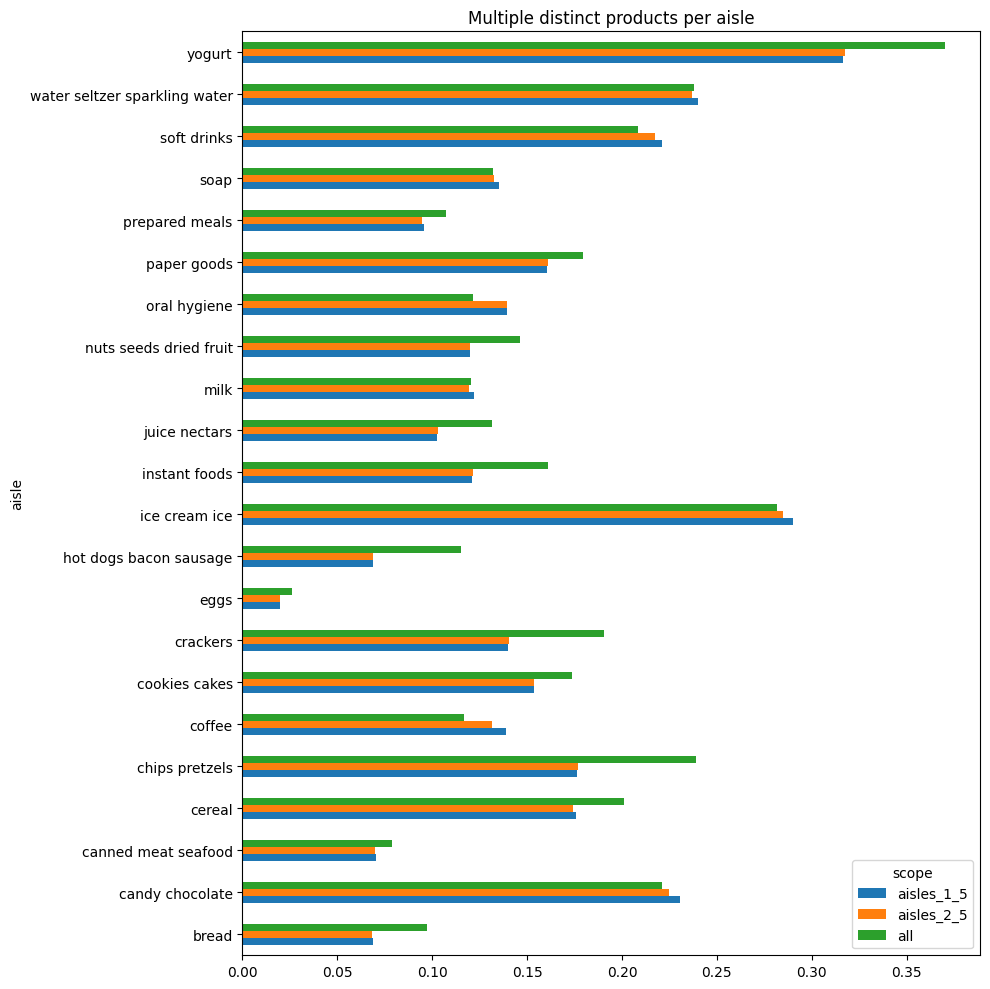

In [6]:
def multi_rate(mask,label):
    a=A[mask]
    den=np.asarray((a>0).sum(axis=0)).ravel()
    num=np.asarray((a>=2).sum(axis=0)).ravel()
    return pd.DataFrame({'scope':label,'aisle_id':aisle_ids,'orders':den,'multi_orders':num,'multi_rate':np.divide(num,den,out=np.full(len(den),np.nan),where=den>0)})
small=(sizes>=2)&(sizes<=5)
# 동일 코너만 구매한 주문도 분석해야 하므로 전체 주문과 1~5 코너도 포함
multi=pd.concat([multi_rate(sizes>0,'all'),multi_rate((sizes>=1)&(sizes<=5),'aisles_1_5'),multi_rate(small,'aisles_2_5')],ignore_index=True).merge(aisles,on='aisle_id')
focus=multi[multi.aisle_id.isin(OURS.aisle_id)]
display(focus[focus.scope.eq('all')].sort_values('multi_rate',ascending=False))
focus.pivot(index='aisle',columns='scope',values='multi_rate').plot.barh(figsize=(10,10),title='Multiple distinct products per aisle'); plt.tight_layout(); plt.show()

## 6. S/C — 동시 구매, Support, Confidence, Lift
S는 동일 코너의 서로 다른 매핑 상품군, C는 서로 다른 코너의 연관성이다. 1~5 코너와 2~5 코너 조건도 저장하여 나중에 검증한다. 최소 동시 구매 기준은 표시만 하고 원시 점수를 제거하지 않는다. S는 현재 참치/스팸만 비교 가능하다. 관측이 없으면 0과 미측정을 구분한다.

In [7]:
def stats(matrix,mask):
    m=matrix[mask].astype(np.int64)
    N=m.shape[0]
    if N==0: raise ValueError('선택된 주문 없음')
    co=(m.T @ m).toarray()
    d=np.diag(co).astype(float)
    conf=np.divide(co,d[:,None],out=np.zeros_like(co,dtype=float),where=d[:,None]>0)
    denom=np.outer(d,d)
    lift=np.divide(co.astype(float)*N,denom,out=np.zeros_like(co,dtype=float),where=denom>0)
    return N,co,d,conf,lift

def pair_table(matrix,mask,ids,scope):
    N,co,d,conf,lift=stats(matrix,mask)
    return pd.DataFrame([{'scope':scope,'source':a,'target':b,'n_orders':N,'source_count':int(d[i]),'target_count':int(d[j]),'count':int(co[i,j]),'support':co[i,j]/N,'confidence':conf[i,j],'lift':lift[i,j],'observed':bool(d[i]>0 and d[j]>0),'meets_min_count':bool(co[i,j]>=MIN_COUNT)} for i,a in enumerate(ids) for j,b in enumerate(ids) if i!=j])
scopes={'all':sizes>0,'aisles_1_5':(sizes>=1)&(sizes<=5),'aisles_2_5':small}
item_aisle=OURS.set_index('id').aisle_id.to_dict()
s_tables=[]; c_tables=[]
for scope,mask in scopes.items():
    st=pair_table(G,mask,item_ids,scope)
    st=st[st.source.map(item_aisle).eq(st.target.map(item_aisle))]
    s_tables.append(st)
    ct=pair_table(X,mask,aisle_ids,scope)
    ct=ct[ct.source.isin(item_aisle.values()) & ct.target.isin(item_aisle.values())]
    c_tables.append(ct)
S=pd.concat(s_tables,ignore_index=True)
C=pd.concat(c_tables,ignore_index=True)
display(S)
display(C[C.scope.eq('aisles_2_5')].sort_values('lift',ascending=False).head(15))

,scope,source,target,n_orders,source_count,target_count,count,support,confidence,lift,observed,meets_min_count
0,all,tuna_can,spam_can,3214236,34348,733,66,0.000021,0.001922,8.425899,True,False
1,all,spam_can,tuna_can,3214236,733,34348,66,0.000021,0.090041,8.425899,True,False
2,aisles_1_5,tuna_can,spam_can,1369591,5000,93,4,0.000003,0.000800,11.781428,True,False
3,aisles_1_5,spam_can,tuna_can,1369591,93,5000,4,0.000003,0.043011,11.781428,True,False
4,aisles_2_5,tuna_can,spam_can,1167496,4797,91,4,0.000003,0.000834,10.698042,True,False
5,aisles_2_5,spam_can,tuna_can,1167496,91,4797,4,0.000003,0.043956,10.698042,True,False


,scope,source,target,n_orders,source_count,target_count,count,support,confidence,lift,observed,meets_min_count
968,aisles_2_5,20,25,1167496,9898,9036,347,0.000297,0.035058,4.529614,True,True
989,aisles_2_5,25,20,1167496,9036,9898,347,0.000297,0.038402,4.529614,True,True
972,aisles_2_5,20,54,1167496,9898,42080,1386,0.001187,0.140028,3.885040,True,True
1073,aisles_2_5,54,20,1167496,42080,9898,1386,0.001187,0.032937,3.885040,True,True
993,aisles_2_5,25,54,1167496,9036,42080,738,0.000632,0.081673,2.266000,True,True
1074,aisles_2_5,54,25,1167496,42080,9036,738,0.000632,0.017538,2.266000,True,True
1098,aisles_2_5,61,45,1167496,33734,49018,2868,0.002457,0.085018,2.024935,True,True
1057,aisles_2_5,45,61,1167496,49018,33734,2868,0.002457,0.058509,2.024935,True,True
1142,aisles_2_5,78,61,1167496,52840,33734,3067,0.002627,0.058043,2.008808,True,True
1101,aisles_2_5,61,78,1167496,33734,52840,3067,0.002627,0.090917,2.008808,True,True


## 7. 저장 및 다음 단계
R은 평가 전용 희소 행렬로 저장한다. 서비스에 Instacart 고객 ID를 복사하지 않는다. S/C JSON은 모든 후보 관계의 원시 통계량이며 03번에서 정규화·가중합을 구현한다. 기존 웹 JSON과 스키마가 다르므로 그대로 교체하면 안 된다.

In [8]:
mapping.to_csv(OUT/'product_mapping.csv',index=False)
coverage.to_csv(OUT/'mapping_coverage.csv',index=False)
multi.to_csv(OUT/'same_aisle_multi_rate.csv',index=False)
repeat_summary.to_csv(OUT/'repurchase_summary.csv',index=False)
sparse.save_npz(OUT/'repurchase_R.npz',R)
np.save(OUT/'user_ids.npy',np.asarray(user_ids))
np.save(OUT/'user_order_counts.npy',user_total)
S.to_csv(OUT/'same_aisle_scores.csv',index=False)
C.to_csv(OUT/'cross_aisle_scores.csv',index=False)
for name,table in [('same_aisle_scores',S),('cross_aisle_scores',C)]:
    table.to_json(OUT/f'{name}.json',orient='records',force_ascii=False,indent=2)
meta={'source':'Instacart prior only','item_ids':item_ids,'item_aisle':{k:int(v) for k,v in item_aisle.items()},'scope_counts':{k:int(v.sum()) for k,v in scopes.items()},'min_count_provisional':MIN_COUNT,'mapping_review_file_used':approved.exists(),'mapping_note':'Proxy groups, not exact Korean SKUs; manual validation required','schema_version':2}
(OUT/'pattern_metadata.json').write_text(json.dumps(meta,ensure_ascii=False,indent=2))
print('저장 완료:', OUT)
for f in sorted(OUT.iterdir()): print(f.name)

저장 완료: /content/drive/MyDrive/2026_02_ROKEY/07_cobot2/recommender/pattern_analysis_v2
cross_aisle_scores.csv
cross_aisle_scores.json
mapping_coverage.csv
pattern_metadata.json
product_mapping.csv
proposed_mapping.csv
repurchase_R.npz
repurchase_summary.csv
same_aisle_multi_rate.csv
same_aisle_scores.csv
same_aisle_scores.json
user_ids.npy
user_order_counts.npy


## 8. 완료 체크 및 후속 작업
- [ ] 상품 매핑 검토 및 빈 상품군 확인 (특히 스팸)
- [ ] R 점수 범위 및 재구매율 확인
- [ ] 동일 코너 복수 구매율과 참치–스팸 count 확인
- [ ] 기존 2~5 코너 주문 수와 비교 (차이 발생 시 데이터/필터 점검)
- [ ] 03번 노트북: R/S/C 공통 후보 점수, 결측 신호 처리, 인기순 fallback, 장바구니 평균/최대 집계
- [ ] 04번 노트북: train 마지막 주문을 고객 단위 validation/test 분리, 동일 상품군 정답과 후보 사용, Hit@1/3·MRR@3·Coverage 비교, 가중치 탐색

실제 원본 데이터 결과는 실행 후 판단한다. 같은 코너 내 구매율이 높다고 특정 상품이 함께 팔린다고 단정하지 않는다. 동일 코너 분석 범위가 좁으므로 필요시 과자/초콜릿 등 같은 코너의 상품군을 추가하고 매핑을 재검토한다.